# 10장 비전 트랜스포머 — 코드 필사
교재: 자연어처리와 컴퓨터비전 심층학습 10장 (ViT · Swin Transformer · CvT)

## 0. 라이브러리 설치
- `evaluate` : 평가 지표(F1) 불러오기
- `accelerate` : Trainer 실행에 필요

In [1]:
!pip install -q evaluate accelerate

# 10.3 ViT 모델 실습
FashionMNIST(옷 사진 10종류)로 사전 학습된 ViT를 미세 조정

## 예제 10.1 FashionMNIST 다운로드
- 학습 10,000개 / 테스트 1,000개로 **클래스별 균등 샘플링**
- `defaultdict` → 클래스별 인덱스 모으기 / `chain.from_iterable` → 1차원으로 펴기 / `Subset` → 해당 인덱스만 추출

In [2]:
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets

def subset_sampler(dataset, classes, max_len):
    target_idx = defaultdict(list)
    for idx, label in enumerate(dataset.train_labels):
        target_idx[int(label)].append(idx)

    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)


train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=100
)

print(f"Training Data Size : {len(subset_train_dataset)}")
print(f"Testing Data Size : {len(subset_test_dataset)}")
print(train_dataset[0])

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.0MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}
Training Data Size : 10000
Testing Data Size : 1000
(<PIL.Image.Image image mode=L size=28x28 at 0x791EDEC24B90>, 9)


## 예제 10.2 이미지 전처리
- `AutoImageProcessor` : 사전 학습 모델의 전처리 설정(크기·평균·표준편차) 불러오기
- `ToTensor` → `Resize(224)` → `Lambda`(흑백 1채널을 3채널로 복제) → `Normalize`

In [3]:
import torch
from torchvision import transforms
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

print(f"size : {image_processor.size}")
print(f"mean : {image_processor.image_mean}")
print(f"std : {image_processor.image_std}")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

size : SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None)
mean : (0.5, 0.5, 0.5)
std : (0.5, 0.5, 0.5)


## 예제 10.3 ViT 데이터로더 적용
- ViT 입력은 딕셔너리 `{"pixel_values": ..., "labels": ...}`
- `collate_fn`(집합 함수)로 배치를 딕셔너리로 포장

In [4]:
from torch.utils.data import DataLoader

def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {"pixel_values": pixel_values, "labels": labels}

train_dataloader = DataLoader(
    subset_train_dataset,
    batch_size=32,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform),
    drop_last=True
)
valid_dataloader = DataLoader(
    subset_test_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=lambda x: collator(x, transform),
    drop_last=True
)

batch = next(iter(train_dataloader))
for key, value in batch.items():
    print(f"{key} : {value.shape}")

pixel_values : torch.Size([32, 3, 224, 224])
labels : torch.Size([32])


## 예제 10.4 사전 학습된 ViT 모델
- `ViTForImageClassification` : 매개변수만으로 분류기를 10개 클래스로 교체
- `ignore_mismatched_sizes=True` : 분류기 크기가 달라도 새로 만들어 교체

In [5]:
from transformers import ViTForImageClassification

model = ViTForImageClassification.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
    num_labels=len(classes),
    id2label={idx: label for label, idx in class_to_idx.items()},
    label2id=class_to_idx,
    ignore_mismatched_sizes=True
)

print(model.classifier)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Linear(in_features=768, out_features=10, bias=True)


## 예제 10.5 패치 임베딩 확인
- `[32, 3, 224, 224]` → Conv2d(16×16, 간격 16) → `[32, 196, 768]` → [CLS] 추가 → `[32, 197, 768]`

In [6]:
print(model.vit.embeddings)

batch = next(iter(train_dataloader))
print("image shape :", batch["pixel_values"].shape)
print("patch embeddings shape :",
    model.vit.embeddings.patch_embeddings(batch["pixel_values"]).shape
)
print("[CLS] + patch embeddings shape :",
    model.vit.embeddings(batch["pixel_values"]).shape
)

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
image shape : torch.Size([32, 3, 224, 224])
patch embeddings shape : torch.Size([32, 196, 768])
[CLS] + patch embeddings shape : torch.Size([32, 197, 768])


## 예제 10.6 하이퍼파라미터 설정
- `TrainingArguments` : 학습 설정을 모아두는 클래스

> ⚠️ 최신 transformers에서는 `evaluation_strategy` → **`eval_strategy`** 로 이름이 바뀜 (교재 원문은 주석으로 남김)

In [7]:
from transformers import TrainingArguments

args = TrainingArguments(
    output_dir="../models/ViT-FashionMNIST",
    save_strategy="epoch",
    eval_strategy="epoch",  # 교재: evaluation_strategy="epoch"
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.001,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # logging_dir="logs",  # 최신 transformers에서 삭제된 인자 → 주석 처리
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

## 예제 10.7 매크로 평균 F1 점수
- `evaluate.load("f1")` → `np.argmax`로 가장 높은 클래스 선택 → `average="macro"`(클래스별 F1의 단순 평균)

In [8]:
import evaluate
import numpy as np

def compute_metrics(eval_pred):
    metric = evaluate.load("f1")
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    macro_f1 = metric.compute(
        predictions=predictions, references=labels, average="macro"
    )
    return macro_f1

## 예제 10.8 ViT 모델 학습
- 예제 10.1~10.7을 한 번에 모은 **전체 코드** + `Trainer`
- `model_init` : 모델을 함수 형태로 전달 / Trainer가 데이터로더를 내부에서 처리 → 데이터세트 + 집합 함수 전달

> ⚠️ 최신 transformers에서는 Trainer의 `tokenizer` → **`processing_class`** 로 이름이 바뀜

In [9]:
import torch
import evaluate
import numpy as np
from itertools import chain
from collections import defaultdict
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import ViTForImageClassification
from transformers import TrainingArguments, Trainer


def subset_sampler(dataset, classes, max_len):
    target_idx = defaultdict(list)
    for idx, label in enumerate(dataset.train_labels):
        target_idx[int(label)].append(idx)

    indices = list(
        chain.from_iterable(
            [target_idx[idx][:max_len] for idx in range(len(classes))]
        )
    )
    return Subset(dataset, indices)

def model_init(classes, class_to_idx):
    model = ViTForImageClassification.from_pretrained(
        pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
    )
    return model

def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {"pixel_values": pixel_values, "labels": labels}

def compute_metrics(eval_pred):
    metric = evaluate.load("f1")
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=1)
    macro_f1 = metric.compute(
        predictions=predictions, references=labels, average="macro"
    )
    return macro_f1

train_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=True)
test_dataset = datasets.FashionMNIST(root="../datasets", download=True, train=False)

classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

subset_train_dataset = subset_sampler(
    dataset=train_dataset, classes=train_dataset.classes, max_len=1000
)
subset_test_dataset = subset_sampler(
    dataset=test_dataset, classes=test_dataset.classes, max_len=100
)

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="google/vit-base-patch16-224-in21k"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/ViT-FashionMNIST",
    save_strategy="epoch",
    eval_strategy="epoch",  # 교재: evaluation_strategy="epoch"
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.001,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # logging_dir="logs",  # 최신 transformers에서 삭제된 인자 → 주석 처리
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor,  # 교재: tokenizer=image_processor
)
trainer.train()

/usr/local/lib/python3.13/dist-packages/torchvision/datasets/mnist.py:66: UserWarning: train_labels has been renamed targets
  warnings.warn("train_labels has been renamed targets")


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTForImageClassification LOAD REPORT from: google/vit-base-patch16-224-in21k
Key                 | Status     | 
--------------------+------------+-
pooler.dense.bias   | UNEXPECTED | 
pooler.dense.weight | UNEXPECTED | 
classifier.weight   | MISSING    | 
classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,F1
1,0.715737,0.651222,0.885484
2,0.491602,0.486678,0.918686
3,0.426107,0.439329,0.923653


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['vit.layers.0.attention.q_proj.weight', 'vit.layers.0.attention.q_proj.bias', 'vit.layers.0.attention.k_proj.weight', 'vit.layers.0.attention.k_proj.bias', 'vit.layers.0.attention.v_proj.weight', 'vit.layers.0.attention.v_proj.bias', 'vit.layers.0.attention.o_proj.weight', 'vit.layers.0.attention.o_proj.bias', 'vit.layers.0.layernorm_before.weight', 'vit.layers.0.layernorm_before.bias', 'vit.layers.0.layernorm_after.weight', 'vit.layers.0.layernorm_after.bias', 'vit.layers.0.mlp.fc1.weight', 'vit.layers.0.mlp.fc1.bias', 'vit.layers.0.mlp.fc2.weight', 'vit.layers.0.mlp.fc2.bias', 'vit.layers.1.attention.q_proj.weight', 'vit.layers.1.attention.q_proj.bias', 'vit.layers.1.attention.k_proj.weight', 'vit.layers.1.attention.k_proj.bias', 'vit.layers.1.attention.v_proj.weight', 'vit.layers.1.attention.v_proj.bias', 'vit.layers.1.attention.o_proj.weight', 'vit.layers.1.attention.o_proj.bias', 'vit.layers.1.layernorm_before

TrainOutput(global_step=1875, training_loss=0.7118067179361979, metrics={'train_runtime': 1158.7738, 'train_samples_per_second': 25.889, 'train_steps_per_second': 1.618, 'total_flos': 2.32492637712384e+18, 'train_loss': 0.7118067179361979, 'epoch': 3.0})

## 예제 10.9 ViT 모델 성능 평가
- `trainer.predict` → `label_ids`(정답), `predictions.argmax(1)`(예측) → **혼동 행렬**
- 대각선 = 맞힌 개수 / 셔츠를 티셔츠·코트로 오분류하는 경우가 많음

PredictionOutput(predictions=array([[ 3.0131946 , -0.56909955, -0.43073228, ..., -0.46789193,
        -0.52433074, -0.37282503],
       [ 1.7315785 , -0.6958472 , -0.2464475 , ..., -0.7716771 ,
        -0.65274817, -0.6162392 ],
       [ 2.936227  , -0.56162655, -0.3976101 , ..., -0.38766226,
        -0.5481915 , -0.45675015],
       ...,
       [-0.48588142, -0.70356053, -0.5629642 , ...,  0.4035573 ,
        -0.00732962,  3.027637  ],
       [-0.2703831 , -0.61799335, -0.6183779 , ...,  0.1345012 ,
        -0.46870208,  3.2221892 ],
       [-0.31444362, -0.5531966 , -0.5787387 , ..., -0.24175851,
        -0.3037685 ,  3.203623  ]], dtype=float32), label_ids=array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

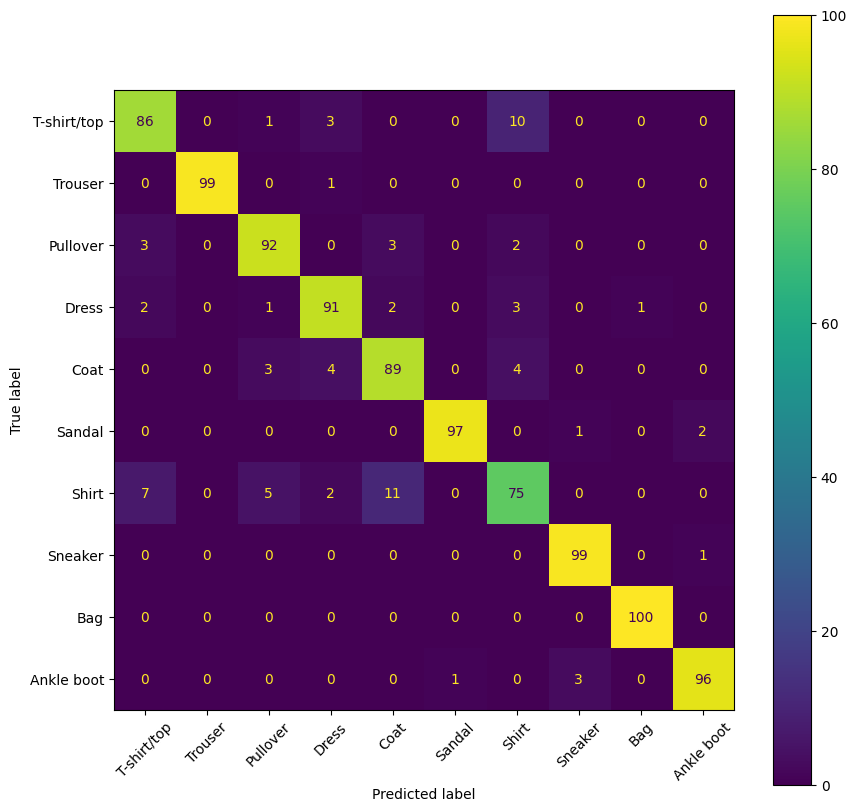

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)
print(outputs)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()

# 10.4 스윈 트랜스포머 (Swin Transformer)
로컬 윈도우 안에서만 어텐션(W-MSA) + 윈도우를 밀어서(SW-MSA) 윈도우끼리 연결 + 상대적 위치 편향

## 예제 10.10 상대적 위치 편향 계산 (①, ② 연산)
- `meshgrid`로 2×2 윈도우의 좌표 격자 생성 → `flatten` → 모든 패치 쌍의 좌표 차이
- 출력 shape `[2, 4, 4]` = (X·Y 2개 축, 패치 4 × 패치 4)

In [11]:
import torch

window_size = 2
coords_h = torch.arange(window_size)
coords_w = torch.arange(window_size)
coords = torch.stack(torch.meshgrid([coords_h, coords_w], indexing="ij"))
coords_flatten = torch.flatten(coords, 1)
relative_coords = coords_flatten[:, :, None] - coords_flatten[:, None, :]

print(relative_coords)  # ①, ②번 연산 과정
print(relative_coords.shape)

tensor([[[ 0,  0, -1, -1],
         [ 0,  0, -1, -1],
         [ 1,  1,  0,  0],
         [ 1,  1,  0,  0]],

        [[ 0, -1,  0, -1],
         [ 1,  0,  1,  0],
         [ 0, -1,  0, -1],
         [ 1,  0,  1,  0]]])
torch.Size([2, 4, 4])


## 예제 10.11 X, Y축에 대한 위치 행렬 (③, ④, ⑤ 연산)
- ③ `+ (window_size - 1)` : 음수 없애기
- ④ X에 `× (2 * window_size - 1)` : X·Y 조합이 겹치지 않게 자릿수 분리
- ⑤ X + Y → 0~8 상대적 위치 인덱스

In [12]:
x_coords = relative_coords[0, :, :]
y_coords = relative_coords[1, :, :]

x_coords += window_size - 1  # X축에 대한 ③번 연산 과정
y_coords += window_size - 1  # Y축에 대한 ③번 연산 과정
x_coords *= 2 * window_size - 1  # ④번 연산 과정
print(f"X축에 대한 행렬:\n{x_coords}\n")
print(f"Y축에 대한 행렬:\n{y_coords}\n")

relative_position_index = x_coords + y_coords  # ⑤번 연산 과정
print(f"X, Y축에 대한 위치 행렬:\n{relative_position_index}")

X축에 대한 행렬:
tensor([[3, 3, 0, 0],
        [3, 3, 0, 0],
        [6, 6, 3, 3],
        [6, 6, 3, 3]])

Y축에 대한 행렬:
tensor([[1, 0, 1, 0],
        [2, 1, 2, 1],
        [1, 0, 1, 0],
        [2, 1, 2, 1]])

X, Y축에 대한 위치 행렬:
tensor([[4, 3, 1, 0],
        [5, 4, 2, 1],
        [7, 6, 4, 3],
        [8, 7, 5, 4]])


## 예제 10.12 X, Y축에 대한 상대적 위치 좌표 변환
- `relative_position_bias_table` : 헤드별 0~8번, 9개의 상대적 위치 편향 테이블
- 인덱스로 편향 값을 불러와 패치 i → 패치 j 어텐션 값에 더해질 텐서로 재구성

In [13]:
num_heads = 1
relative_position_bias_table = torch.Tensor(
    torch.zeros((2 * window_size - 1) * (2 * window_size - 1), num_heads)
)

relative_position_bias = relative_position_bias_table[relative_position_index.view(-1)]
relative_position_bias = relative_position_bias.view(
    window_size * window_size, window_size * window_size, -1
)
print(relative_position_bias.shape)

torch.Size([4, 4, 1])


## 예제 10.13 사전 학습된 스윈 트랜스포머 모델
- `microsoft/swin-tiny-patch4-window7-224` : 4×4 패치, 7×7 로컬 윈도우, 224×224 이미지
- 데이터세트 코드는 예제 10.1, 10.2, 10.3 그대로 사용
- `named_children()` 중첩 for문으로 모듈 구조를 트리 형태로 출력

In [14]:
from transformers import SwinForImageClassification

model = SwinForImageClassification.from_pretrained(
    pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("└", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("│  └", ssub_name)
            for sssub_name, sssub_module in ssub_module.named_children():
                if sssub_name == "projection":
                    print("│  │  └", sssub_name, sssub_module)
                else:
                    print("│  │  └", sssub_name)

config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


swin
└ embeddings
│  └ patch_embeddings
│  │  └ projection Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
│  └ norm
│  └ dropout
└ encoder
│  └ layers
│  │  └ 0
│  │  └ 1
│  │  └ 2
│  │  └ 3
└ layernorm
└ pooler
classifier


## 예제 10.14 패치 임베딩 모듈
- Conv2d(4×4, 간격 4) → (224 − 4)/4 + 1 = 56 → 56 × 56 = **3,136개** 패치, **96**채널
- [CLS] 토큰 없음 (분류는 토큰 평균값 사용)

In [15]:
batch = next(iter(train_dataloader))
print("이미지 차원 :", batch["pixel_values"].shape)

patch_emb_output, shape = model.swin.embeddings.patch_embeddings(batch["pixel_values"])
print("모듈:", model.swin.embeddings.patch_embeddings)
print("패치 임베딩 차원 :", patch_emb_output.shape)

이미지 차원 : torch.Size([32, 3, 224, 224])
모듈: SwinPatchEmbeddings(
  (projection): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
)
패치 임베딩 차원 : torch.Size([32, 3136, 96])


## 예제 10.15 스윈 트랜스포머 블록
- 첫 번째 스테이지 = `blocks`(스윈 블록) + `downsample`(패치 병합)

In [16]:
for main_name, main_module in model.swin.encoder.layers[0].named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("└", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("│  └", ssub_name)

blocks
└ 0
│  └ attention
│  └ layernorm_before
│  └ layernorm_after
│  └ mlp
│  └ dropout
│  └ drop_path
└ 1
│  └ attention
│  └ layernorm_before
│  └ layernorm_after
│  └ mlp
│  └ dropout
│  └ drop_path
downsample
└ reduction
└ norm


## 예제 10.16 SwinLayer 구조
- `layernorm_before` → `attention`(W-MSA / SW-MSA) → `drop_path` → `layernorm_after` → `intermediate`(96→384 + GELU) → `output`(384→96)

In [17]:
print(model.swin.encoder.layers[0].blocks[0])

SwinLayer(
  (attention): SwinAttention(
    (q_proj): Linear(in_features=96, out_features=96, bias=True)
    (k_proj): Linear(in_features=96, out_features=96, bias=True)
    (v_proj): Linear(in_features=96, out_features=96, bias=True)
    (o_proj): Linear(in_features=96, out_features=96, bias=True)
    (relative_position_bias): SwinRelativePositionBias()
  )
  (layernorm_before): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (layernorm_after): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
  (mlp): SwinMLP(
    (activation_fn): GELUActivation()
    (fc1): Linear(in_features=96, out_features=384, bias=True)
    (fc2): Linear(in_features=384, out_features=96, bias=True)
  )
  (dropout): Dropout(p=0.0, inplace=False)
  (drop_path): Identity()
)


## 예제 10.17 W-MSA, SW-MSA 모듈
- `blocks[0]` = W-MSA, `blocks[1]` = SW-MSA
- 입력·출력 차원 모두 `[32, 3136, 96]`로 동일

In [18]:
print("패치 임베딩 차원 :", patch_emb_output.shape)

W_MSA = model.swin.encoder.layers[0].blocks[0]
SW_MSA = model.swin.encoder.layers[0].blocks[1]

W_MSA_output = W_MSA(patch_emb_output, W_MSA.input_resolution)[0]
SW_MSA_output = SW_MSA(W_MSA_output, SW_MSA.input_resolution)[0]

print("W-MSA 결과 차원 :", W_MSA_output.shape)
print("SW-MSA 결과 차원 :", SW_MSA_output.shape)

패치 임베딩 차원 : torch.Size([32, 3136, 96])
W-MSA 결과 차원 : torch.Size([32, 3136, 96])
SW-MSA 결과 차원 : torch.Size([32, 3136, 96])


## 예제 10.18 패치 병합
- 56×56 패치를 4그룹으로 나눠 채널에 병합 (96 × 4 = 384) → `reduction` Linear로 절반(192)
- 결과 `[32, 784(28×28), 192]`

In [20]:
patch_merge = model.swin.encoder.layers[0].downsample
print("patch_merge 모듈 :", patch_merge)

output = patch_merge(SW_MSA_output, SW_MSA.input_resolution)  # 교재: patch_merge.input_resolution
print("patch_merge 결과 차원 :", output.shape)

patch_merge 모듈 : SwinPatchMerging(
  (reduction): Linear(in_features=384, out_features=192, bias=False)
  (norm): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
)
patch_merge 결과 차원 : torch.Size([32, 784, 192])


## 예제 10.19 스윈 트랜스포머 모델 학습
- 예제 10.8에서 **사전 학습 모델 · 이미지 프로세서 · 출력 디렉터리**만 변경
- 교재는 변경 점만 실었지만, 여기서는 바로 실행되도록 transform · Trainer까지 포함 (함수 `collator`, `compute_metrics`, 데이터세트는 위에서 정의한 것 재사용)

In [21]:
from transformers import SwinForImageClassification

def model_init(classes, class_to_idx):
    model = SwinForImageClassification.from_pretrained(
        pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
        ignore_mismatched_sizes=True
    )
    return model

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="microsoft/swin-tiny-patch4-window7-224"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["height"],
                image_processor.size["width"]
            )
        ),
        transforms.Lambda(
            lambda x: torch.cat([x, x, x], 0)
        ),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/Swin-FashionMNIST",
    save_strategy="epoch",
    eval_strategy="epoch",  # 교재: evaluation_strategy="epoch"
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.001,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # logging_dir="logs",  # 최신 transformers에서 삭제된 인자 → 주석 처리
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor,  # 교재: tokenizer=image_processor
)
trainer.train()

preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['swin.encoder.layers.0.blocks.0.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.k_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.k_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.v_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.v_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.o_proj.weight', 'swin.encoder.layers.0.blocks.0.attention.o_proj.bias', 'swin.encoder.layers.0.blocks.0.attention.relative_position_bias.relative_position_bias_table', 'swin.encoder.layers.0.blocks.0.mlp.fc1.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc1.bias', 'swin.encoder.layers.0.blocks.0.mlp.fc2.weight', 'swin.encoder.layers.0.blocks.0.mlp.fc2.bias', 'swin.encoder.layers.0.blocks.1.attention.q_proj.weight', 'swin.encoder.layers.0.blocks.1.attention.q_proj.bias', 'swin.encoder.layers.0.blocks.1.attention.k_proj.weight', 'swin.encode

TrainOutput(global_step=1875, training_loss=0.3642571319580078, metrics={'train_runtime': 469.164, 'train_samples_per_second': 63.944, 'train_steps_per_second': 3.996, 'total_flos': 7.4584635826176e+17, 'train_loss': 0.3642571319580078, 'epoch': 3.0})

### 스윈 트랜스포머 성능 평가 (예제 10.9 코드 재사용)
- 셔츠 예측 개선(72 → 77), 검증 손실 대폭 감소(0.4357 → 0.2416)

{'test_loss': 0.23041094839572906, 'test_f1': 0.9161550085149095, 'test_runtime': 5.5971, 'test_samples_per_second': 178.664, 'test_steps_per_second': 11.256}


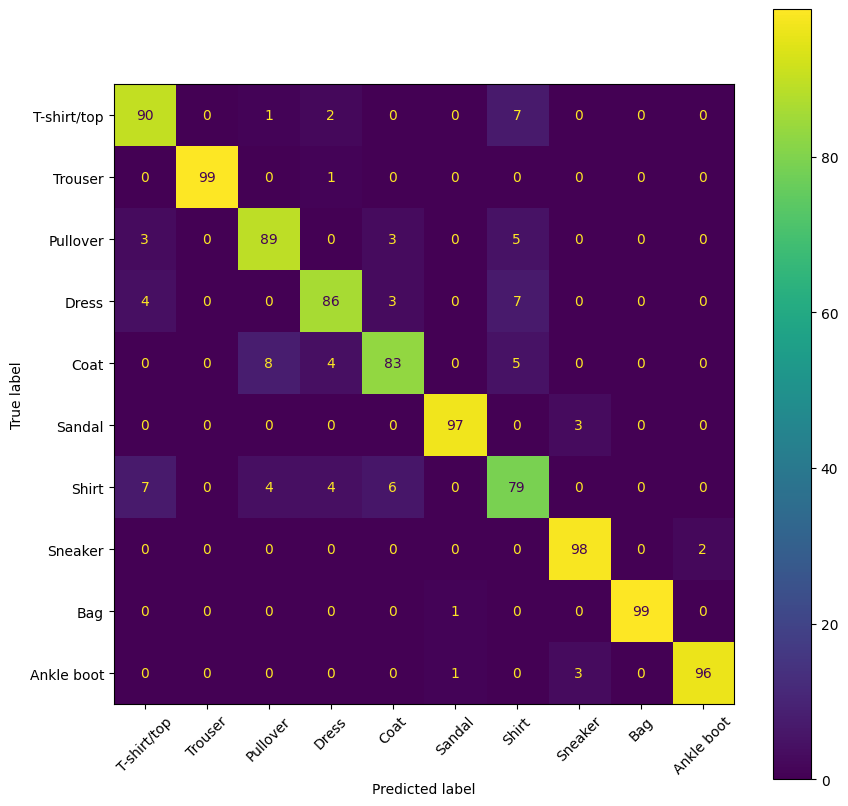

In [22]:
outputs = trainer.predict(subset_test_dataset)
print(outputs.metrics)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()

# 10.5 CvT (Convolutional Vision Transformer)
합성곱으로 패치 임베딩 + Q·K·V 임베딩 → 위치 임베딩 불필요, 키·값 축소(간격 2)로 연산량 감소

## 예제 10.20 CvT 모델 이미지 데이터 전처리
- `microsoft/cvt-21` (ImageNet-1k, 224×224)
- CvT 이미지 프로세서는 height/width 대신 **`shortest_edge`**(너비·높이 중 짧은 쪽) 키 사용

In [23]:
from transformers import AutoImageProcessor

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="microsoft/cvt-21"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["shortest_edge"],
                image_processor.size["shortest_edge"]
            )
        ),
        transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

preprocessor_config.json:   0%|          | 0.00/266 [00:00<?, ?B/s]

## 예제 10.21 사전 학습된 CvT 모델
- 구조: `cvt` → encoder → stages(0, 1, 2) / `layernorm` / `classifier`
- 스윈과 달리 3개 스테이지, 분류기 앞 pooler 없음

In [24]:
from transformers import CvtForImageClassification

model = CvtForImageClassification.from_pretrained(
    pretrained_model_name_or_path="microsoft/cvt-21",
    num_labels=len(train_dataset.classes),
    id2label={idx: label for label, idx in train_dataset.class_to_idx.items()},
    label2id=train_dataset.class_to_idx,
    ignore_mismatched_sizes=True
)

for main_name, main_module in model.named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("└", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("   └", ssub_name)
            for sssub_name, sssub_module in ssub_module.named_children():
                print("      └", sssub_name)

config.json:   0%|          | 0.00/70.3k [00:00<?, ?B/s]

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  127MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


cvt
└ encoder
   └ stages
      └ 0
      └ 1
      └ 2
layernorm
classifier


## 예제 10.22 CvT 모델의 스테이지 구조
- `CvtEmbeddings` : Conv2d(3→64, 7×7, 간격 4, 패딩 2) → (224 − 7 + 2×2)/4 + 1 = 56.25 → 56
- `CvtLayer` : 쿼리 Conv(간격 1), 키·값 Conv(**간격 2**) / `groups=64` = 깊이별(분리 가능한) 합성곱

In [25]:
stages = model.cvt.encoder.stages
print(stages[0])

CvtStage(
  (embedding): CvtEmbeddings(
    (convolution_embeddings): CvtConvEmbeddings(
      (projection): Conv2d(3, 64, kernel_size=(7, 7), stride=(4, 4), padding=(2, 2))
      (normalization): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (layers): Sequential(
    (0): CvtLayer(
      (attention): CvtAttention(
        (attention): CvtSelfAttention(
          (convolution_projection_query): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAttentionConvProjection(
              (convolution): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=64, bias=False)
              (normalization): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            )
            (linear_projection): CvtSelfAttentionLinearProjection()
          )
          (convolution_projection_key): CvtSelfAttentionProjection(
            (convolution_projection): CvtSelfAtte

## 예제 10.23 셀프 어텐션 적용
- 패치 임베딩 `[32, 64, 56, 56]` → `view` + `permute` → `[32, 3136, 64]` → 셀프 어텐션 → `[32, 3136, 64]`

In [26]:
batch = next(iter(train_dataloader))
print("이미지 차원 :", batch["pixel_values"].shape)

patch_emb_output = stages[0].embedding(batch["pixel_values"])
print("패치 임베딩 차원 :", patch_emb_output.shape)

batch_size, num_channels, height, width = patch_emb_output.shape
hidden_state = patch_emb_output.view(batch_size, num_channels, height * width).permute(0, 2, 1)
print("셀프 어텐션 입력 차원 :", hidden_state.shape)

attention_output = stages[0].layers[0].attention.attention(hidden_state, height, width)
print("셀프 어텐션 출력 차원 :", attention_output.shape)

이미지 차원 : torch.Size([32, 3, 224, 224])
패치 임베딩 차원 : torch.Size([32, 64, 56, 56])
셀프 어텐션 입력 차원 : torch.Size([32, 3136, 64])
셀프 어텐션 출력 차원 : torch.Size([32, 3136, 64])


## 예제 10.24 CvT 모델 학습
- 예제 10.8에서 **사전 학습 모델 · 전처리 · 출력 디렉터리**만 변경
- 교재는 변경 점만 실었지만, 바로 실행되도록 Trainer까지 포함

In [27]:
from transformers import CvtForImageClassification

def model_init(classes, class_to_idx):
    model = CvtForImageClassification.from_pretrained(
        pretrained_model_name_or_path="microsoft/cvt-21",
        num_labels=len(classes),
        id2label={idx: label for label, idx in class_to_idx.items()},
        label2id=class_to_idx,
        ignore_mismatched_sizes=True
    )
    return model

image_processor = AutoImageProcessor.from_pretrained(
    pretrained_model_name_or_path="microsoft/cvt-21"
)

transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Resize(
            size=(
                image_processor.size["shortest_edge"],
                image_processor.size["shortest_edge"]
            )
        ),
        transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),
        transforms.Normalize(
            mean=image_processor.image_mean,
            std=image_processor.image_std
        )
    ]
)

args = TrainingArguments(
    output_dir="../models/CvT-FashionMNIST",
    save_strategy="epoch",
    eval_strategy="epoch",  # 교재: evaluation_strategy="epoch"
    learning_rate=1e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.001,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    # logging_dir="logs",  # 최신 transformers에서 삭제된 인자 → 주석 처리
    logging_steps=125,
    remove_unused_columns=False,
    seed=7
)

trainer = Trainer(
    model_init=lambda x: model_init(classes, class_to_idx),
    args=args,
    train_dataset=subset_train_dataset,
    eval_dataset=subset_test_dataset,
    data_collator=lambda x: collator(x, transform),
    compute_metrics=compute_metrics,
    processing_class=image_processor,  # 교재: tokenizer=image_processor
)
trainer.train()

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/731 [00:00<?, ?it/s]

[transformers] CvtForImageClassification LOAD REPORT from: microsoft/cvt-21
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 384]) vs model:torch.Size([10, 384])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch,Training Loss,Validation Loss,F1
1,0.809211,0.333426,0.878060
2,0.692400,0.276780,0.908980
3,0.676121,0.267991,0.914133


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1875, training_loss=0.7988334025065105, metrics={'train_runtime': 770.4113, 'train_samples_per_second': 38.94, 'train_steps_per_second': 2.434, 'total_flos': 8.4649093853184e+17, 'train_loss': 0.7988334025065105, 'epoch': 3.0})

### CvT 성능 평가 (예제 10.9 코드 재사용)

{'test_loss': 0.2679913640022278, 'test_f1': 0.9141332652145984, 'test_runtime': 7.9313, 'test_samples_per_second': 126.083, 'test_steps_per_second': 7.943}


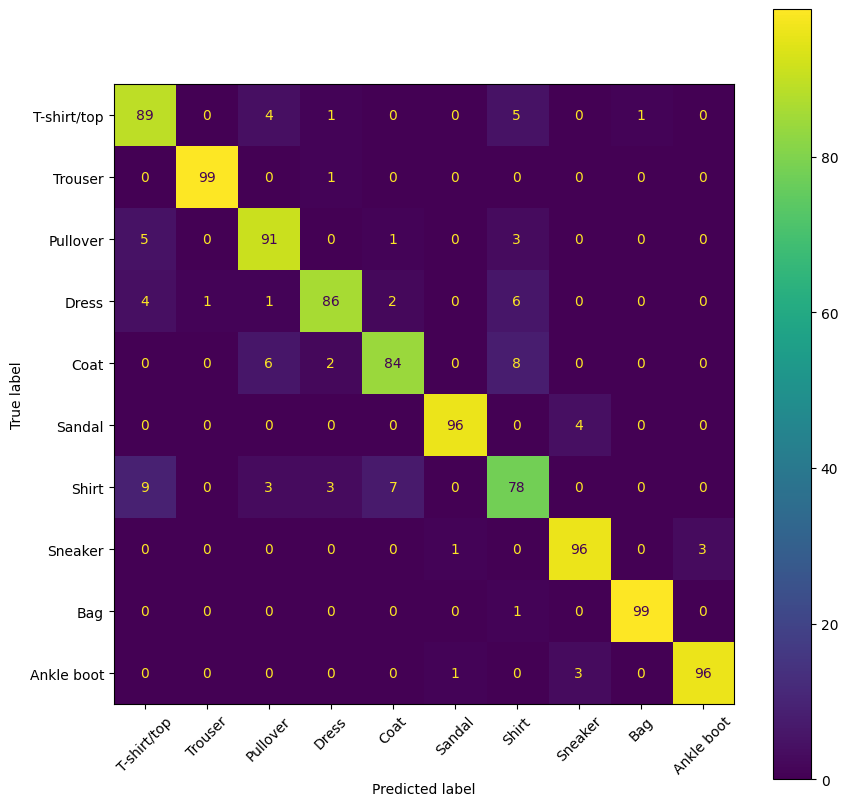

In [28]:
outputs = trainer.predict(subset_test_dataset)
print(outputs.metrics)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)

labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=labels)
_, ax = plt.subplots(figsize=(10, 10))
display.plot(xticks_rotation=45, ax=ax)
plt.show()